# Montecarlo: call asiática sobre WMT, MRK y NVDA

Valoramos una call asiática sobre una cesta de tres acciones (WMT, MRK y NVDA). Es una call porque solo paga si la cesta supera el strike, y es asiática porque el pago depende de la media de los precios durante los 5 años y no del precio final.

El Montecarlo lo hacemos en dos partes. Primero simulamos los 5 primeros trimestres una sola vez, y ese comienzo es el mismo para todas las simulaciones. Después, desde el precio del trimestre 5, simulamos 100.000 veces los 15 trimestres que faltan. Con los 20 precios de cada simulación sacamos el payoff de la cesta, y la media de todos los payoffs traída a hoy es la prima.

## 1. Parámetros

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

acciones = ["WMT", "MRK", "NVDA"]
S0 = np.array([1.0, 1.0, 1.0])      # precios iniciales normalizados
mu = 0.01                           # tasa libre de riesgo
E = 3.0                             # strike de la cesta
T = 5                               # años
n_times = 20                        # trimestres en total
n_comunes = 5                       # trimestres del comienzo
n_resto = n_times - n_comunes       # trimestres del resto de la trayectoria (15)
n_finales = 100_000                 # número de simulaciones

dt = T / n_times                    # 0,25 años: un trimestre

## 2. Volatilidad anual y correlación

Las sacamos en **seleccioncartera.ipynb** con las log-rentabilidades diarias de los precios ajustados (de junio de 2018 a diciembre de 2025), pasando la volatilidad a anual con √252. Aquí copiamos el resultado a mano.

In [13]:
sigma = np.array([0.21915220410541955, 0.23593283496457446, 0.5174176492623017])   # volatilidad anual: WMT, MRK, NVDA

rho = np.array([[1.0,                 0.23448266076590554, 0.2254536587614545 ],
                [0.23448266076590554, 1.0,                 0.12948744681423088],
                [0.2254536587614545,  0.12948744681423088, 1.0                ]])   # matriz de correlaciones 3x3

pd.DataFrame(rho, index=acciones, columns=acciones).round(3)

,WMT,MRK,NVDA
WMT,1.000,0.234,0.225
MRK,0.234,1.000,0.129
NVDA,0.225,0.129,1.000


## 3. Cholesky

Descomponemos la matriz de correlaciones como $\rho = L \cdot L^t$. Al multiplicar las normales por $L^t$ quedan correlacionadas como las acciones reales.

In [14]:
L = np.linalg.cholesky(rho)
L

array([[1.        , 0.        , 0.        ],
       [0.23448266, 0.9721203 , 0.        ],
       [0.22545366, 0.07881995, 0.97106028]])

## 4. Comienzo (trimestres 1 a 5)

Simulamos una sola trayectoria de las tres acciones. En cada trimestre el precio se multiplica por $e = e^{(\mu - \sigma^2/2)\Delta t + \sigma Z \sqrt{\Delta t}}$. Aquí $Z$ es un número aleatorio de una normal estándar, ya correlacionado con Cholesky. Con **cumprod** vamos acumulando esos factores desde $S_0$.

In [15]:
rng = np.random.default_rng(11)

Z1 = rng.standard_normal((n_comunes, 3)) @ L.T
e1 = np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z1 * np.sqrt(dt))

S1 = np.empty((n_comunes + 1, 3))
S1[0] = S0
S1[1:] = e1
S1 = np.cumprod(S1, axis=0)          # trimestres 0 a 5: (6, 3)
pd.DataFrame(S1, columns=acciones).round(3)

,WMT,MRK,NVDA
0,1.000,1.000,1.000
1,1.000,1.165,1.359
2,0.943,1.105,1.113
3,1.000,1.110,1.344
4,0.814,1.257,1.179
5,0.874,1.255,1.079


## 5. Resto de la trayectoria (trimestres 6 a 20)

Simulamos **n_finales** = 100.000 trayectorias de los trimestres 6 a 20, y todas empiezan en el precio del trimestre 5.

In [16]:
Z2 = rng.standard_normal((n_finales, n_resto, 3)) @ L.T
e2 = np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z2 * np.sqrt(dt))

S2 = np.empty((n_finales, n_resto + 1, 3))
S2[:, 0, :] = S1[-1]                 # todas empiezan en el precio del trimestre 5
S2[:, 1:, :] = e2
S2 = np.cumprod(S2, axis=1)          # trimestres 5 a 20: (n_finales, 16, 3)

Juntamos el comienzo y el resto de la trayectoria en la matriz **X**, de dimensiones (simulaciones, pasos, activos) = (100.000, 20, 3).

Cada elemento **X[m, n, k]** es el precio de la acción k en el trimestre n de la simulación m, dividido por su precio inicial. Aquí m va de 1 a 100.000, n de 1 a 20 y k recorre WMT, MRK y NVDA. Un valor de 1,16 significa que la acción está un 16 % por encima de como empezó. Cada simulación es un futuro posible.

Los 5 primeros trimestres **(n=1 a 5)** son iguales en todas las simulaciones **(m)** y los 15 siguientes **(n=6 a 20)**  cambian. El precio inicial $S_0$ se queda fuera porque no entra en la media geométrica.

In [17]:
X = np.concatenate([np.broadcast_to(S1[1:], (n_finales, n_comunes, 3)), S2[:, 1:]], axis=1)
print("Dimensión de X:", X.shape)
X

Dimensión de X: (100000, 20, 3)


array([[[1.00024328, 1.16464962, 1.3585706 ],
        [0.94253929, 1.10481311, 1.11308665],
        [0.99974729, 1.11020876, 1.34432618],
        ...,
        [0.69331025, 0.93477026, 0.38938259],
        [0.76715792, 0.82018458, 0.45323468],
        [0.81667331, 0.67791859, 0.47901804]],

       [[1.00024328, 1.16464962, 1.3585706 ],
        [0.94253929, 1.10481311, 1.11308665],
        [0.99974729, 1.11020876, 1.34432618],
        ...,
        [1.46234062, 1.15578718, 1.78035521],
        [1.42505405, 1.05175541, 1.85201721],
        [1.46879528, 1.04483151, 1.72577982]],

       [[1.00024328, 1.16464962, 1.3585706 ],
        [0.94253929, 1.10481311, 1.11308665],
        [0.99974729, 1.11020876, 1.34432618],
        ...,
        [1.20925285, 0.84016826, 1.27684041],
        [1.13486363, 0.81516102, 1.27483354],
        [1.08966978, 0.64480652, 1.14419162]],

       ...,

       [[1.00024328, 1.16464962, 1.3585706 ],
        [0.94253929, 1.10481311, 1.11308665],
        [0.99974729, 1

## 6. Payoff y prima

En cada simulación calculamos la media geométrica normalizada de los 20 precios de cada acción (los 5 del comienzo y los 15 de esa simulación). Sumamos las medias de las tres acciones y el payoff es **max(suma − E, 0)**.

La prima es la media de los payoffs traída a hoy con $e^{-\mu T}$. El error estándar indica cuánto podría cambiar la prima por haber hecho un número finito de simulaciones. También llevamos la prima al año 5, que es cuando se cobra el payoff, para poder compararlos.

In [18]:
G = np.exp(np.log(X / S0).mean(axis=1))   # media geométrica de los 20 precios de cada acción: (n_finales, 3)
cesta = G.sum(axis=1)                # suma de las tres medias: (n_finales,)
payoff = np.maximum(cesta - E, 0)    # lo que paga la opción en el año 5

prima = np.exp(-mu * T) * payoff.mean()
error = np.exp(-mu * T) * payoff.std(ddof=1) / np.sqrt(n_finales)
prima_final = prima * np.exp(mu * T)      # la prima llevada al año 5

## 7. Gráficos de las trayectorias

La línea gruesa es el comienzo, las finas son simulaciones de los trimestres 6 a 20 y la discontinua es la media de todas las simulaciones. Primero va cada empresa por separado y después las tres juntas, con solo 10 simulaciones para que se lea mejor.

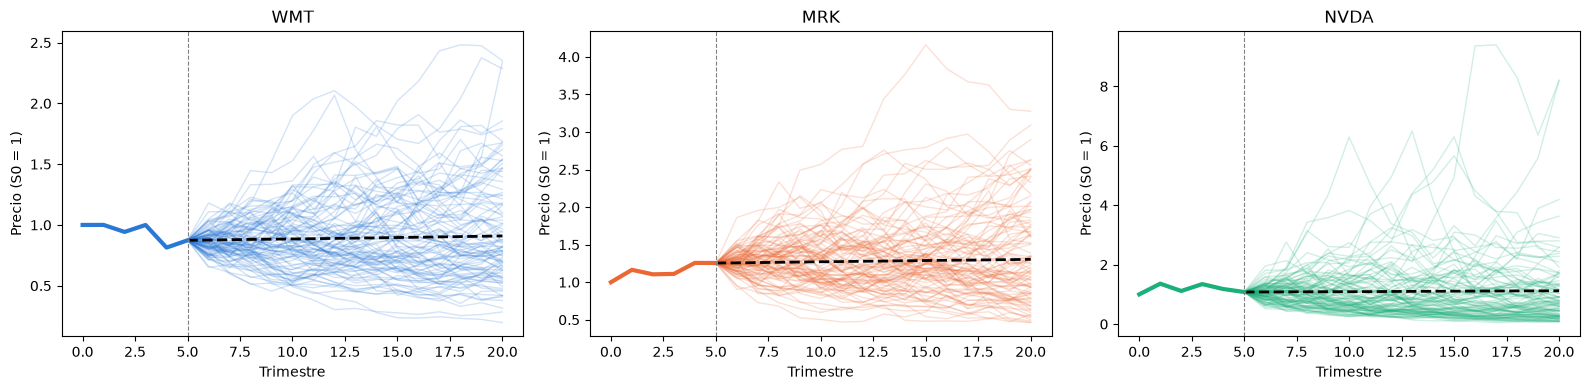

In [20]:
colores = ["#2a78d6", "#eb6834", "#1baf7a"]
t1 = np.arange(0, n_comunes + 1)
t2 = np.arange(n_comunes, n_times + 1)
media = S2.mean(axis=0)

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for k, ax in enumerate(ejes):
    ax.plot(t2, S2[:100, :, k].T, color=colores[k], lw=1, alpha=0.2)
    ax.plot(t2, media[:, k], color="black", lw=2, ls="--")
    ax.plot(t1, S1[:, k], color=colores[k], lw=3)
    ax.axvline(n_comunes, color="gray", lw=0.8, ls="--")
    ax.set_title(acciones[k]); ax.set_xlabel("Trimestre"); ax.set_ylabel("Precio (S0 = 1)")
plt.tight_layout()
plt.show()


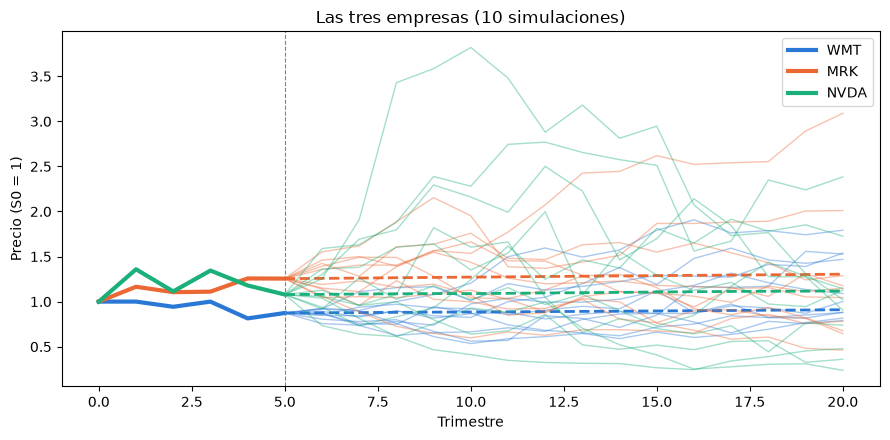

In [ ]:
plt.figure(figsize=(9, 4.5))
for k in range(3):
    plt.plot(t2, S2[:10, :, k].T, color=colores[k], lw=1, alpha=0.4)
    plt.plot(t2, media[:, k], color=colores[k], lw=2, ls="--")
    plt.plot(t1, S1[:, k], color=colores[k], lw=3, label=acciones[k])
plt.axvline(n_comunes, color="gray", lw=0.8, ls="--")
plt.xlabel("Trimestre"); plt.ylabel("Precio (S0 = 1)"); plt.title("Las tres empresas (10 simulaciones)")
plt.legend()
plt.tight_layout()
plt.show()

Este gráfico muestra la cesta, es decir, la suma de los precios de las tres acciones en cada trimestre, junto al strike **E = 3**. Al empezar vale 3 (1 + 1 + 1). El payoff se calcula con la suma de las medias geométricas, así que el gráfico es orientativo: sirve para ver cuántas simulaciones quedan por encima del strike.

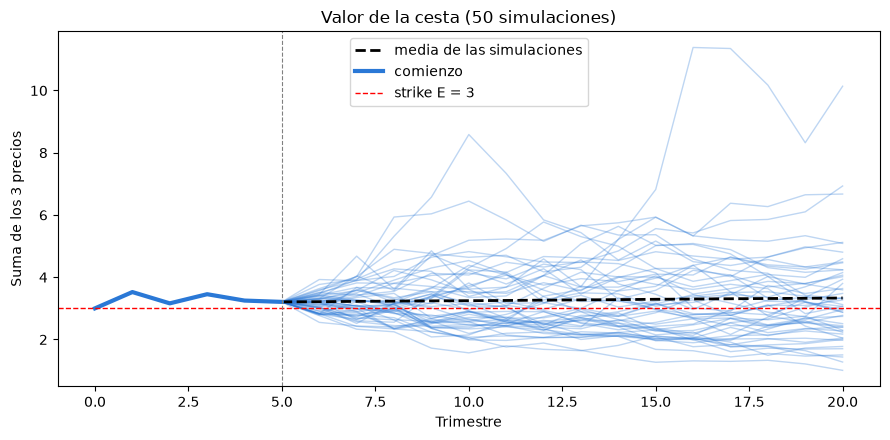

In [ ]:
cesta_comienzo = S1.sum(axis=1)          # (6,)
cesta_finales = S2.sum(axis=2)           # (n_finales, 16)

plt.figure(figsize=(9, 4.5))
plt.plot(t2, cesta_finales[:50].T, color="#2a78d6", lw=1, alpha=0.3)
plt.plot(t2, cesta_finales.mean(axis=0), color="black", lw=2, ls="--", label="media de las simulaciones")
plt.plot(t1, cesta_comienzo, color="#2a78d6", lw=3, label="comienzo")
plt.axhline(E, color="red", lw=1, ls="--", label="strike E = 3")
plt.axvline(n_comunes, color="gray", lw=0.8, ls="--")
plt.xlabel("Trimestre"); plt.ylabel("Suma de los 3 precios"); plt.title("Valor de la cesta (50 simulaciones)")
plt.legend()
plt.show()

## 8. Resultados

### 8.1 Prima

La tabla resume el resultado del Montecarlo: el payoff medio, la prima de la call asiática (ese payoff medio traído a hoy) y su error. Incluye también el porcentaje de simulaciones en las que la opción paga algo y el de las que pagan más de lo que costó la opción, con la prima llevada al año 5.

La prima depende del comienzo de los 5 primeros trimestres, que sale de la semilla 11. Con otra semilla el comienzo sería distinto y la prima también. El error estándar solo mide la variabilidad de los 15 trimestres siguientes, así que la incertidumbre del comienzo queda fuera de él.

In [24]:
resultados = pd.DataFrame({
    "valor": [f"{payoff.mean():.4f}", f"{prima:.4f}", f"{error:.4f}",
              f"{(payoff > 0).mean():.1%}", f"{(payoff > prima_final).mean():.1%}"],
}, index=["Payoff medio (año 5)", "Prima (hoy)", "Error estándar de la prima",
          "Simulaciones con payoff > 0", "Simulaciones con payoff > prima (ganas dinero)"])
resultados

,valor
Payoff medio (año 5),0.3168
Prima (hoy),0.3014
Error estándar de la prima,0.0015
Simulaciones con payoff > 0,53.4%
Simulaciones con payoff > prima (ganas dinero),33.8%


### 8.2 Distribución del payoff

De media, la suma de las medias geométricas sale en torno a 3,14, muy cerca del strike, así que casi la mitad de las simulaciones se queda por debajo de 3 y paga 0. Unas pocas pagan mucho, y por eso la media del payoff queda bastante por encima de la mediana.

In [25]:
pd.Series(payoff, name="payoff").describe().round(4)

count    100000.0000
mean          0.3168
std           0.4842
min           0.0000
25%           0.0000
50%           0.0514
75%           0.4931
max           6.9701
Name: payoff, dtype: float64

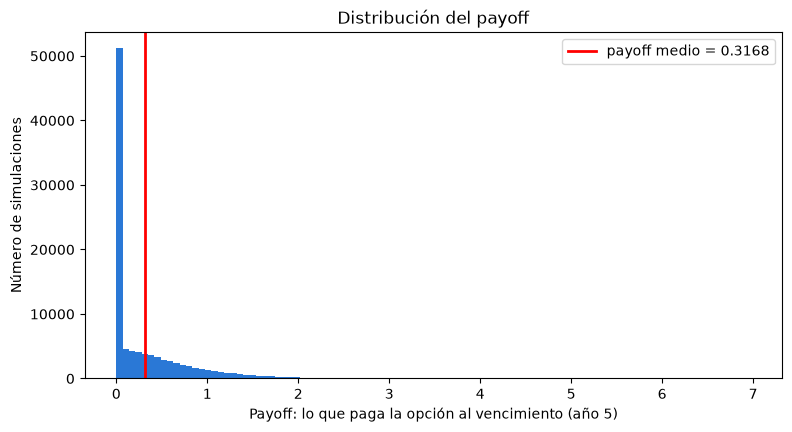

In [26]:
plt.figure(figsize=(9, 4.5))
plt.hist(payoff, bins=100, color="#2a78d6")
plt.axvline(payoff.mean(), color="red", lw=2, label=f"payoff medio = {payoff.mean():.4f}")
plt.xlabel("Payoff: lo que paga la opción al vencimiento (año 5)"); plt.ylabel("Número de simulaciones"); plt.title("Distribución del payoff")
plt.legend()
plt.show()

### 8.3 Ejemplo del cálculo del payoff en 15 simulaciones

De las 100.000 simulaciones mostramos 15 como ejemplo. Para cada una, la media geométrica de los 20 precios de cada acción, la suma de las tres y el payoff **max(suma − 3, 0)**.

In [27]:
tabla = pd.DataFrame(G[:15], columns=acciones).round(3)
tabla["suma"] = tabla.sum(axis=1)
tabla["payoff"] = payoff[:15].round(3)
tabla.index.name = "simulación"
tabla

,WMT,MRK,NVDA,suma,payoff
simulación,,,,,
0,0.734,1.113,0.545,2.392,0.000
1,1.077,1.238,1.311,3.626,0.626
2,0.972,0.975,1.587,3.534,0.535
3,0.891,1.413,1.953,4.257,1.257
4,0.785,0.900,1.876,3.561,0.561
5,1.279,1.758,0.633,3.670,0.670
6,0.897,1.252,0.729,2.878,0.000
7,0.917,1.579,1.290,3.786,0.786
8,1.130,1.105,1.082,3.317,0.316


### 8.4 Probabilidad de que cada acción acabe por encima de su precio inicial

Porcentaje de simulaciones en las que el precio del trimestre 20 es mayor que $S_0 = 1$.

Estos porcentajes dependen del comienzo. En el trimestre 5 WMT ya estaba en 0,87 y MRK en 1,26, y por eso MRK acaba más veces por encima de su precio inicial.

In [28]:
pd.Series((S2[:, -1, :] > S0).mean(axis=0), index=acciones, name="por encima de S0").map("{:.1%}".format)

WMT     33.3%
MRK     63.7%
NVDA    34.9%
Name: por encima de S0, dtype: str

## 9. Fiabilidad del resultado
### 9.1 Convergencia de la prima

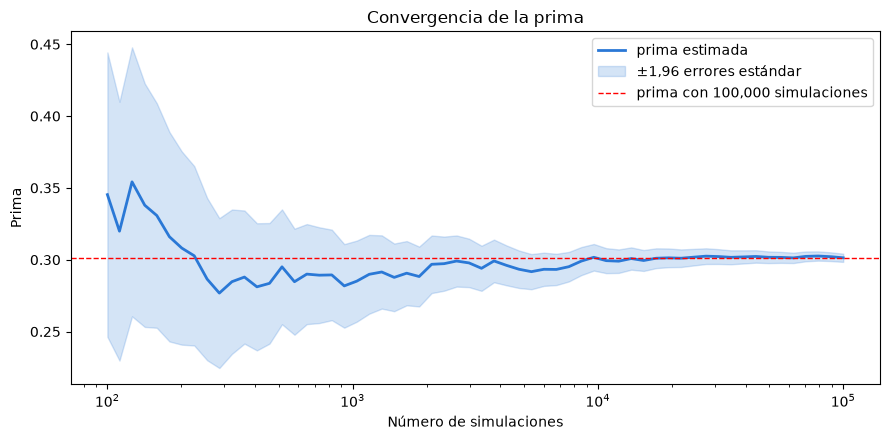

In [17]:
ns = np.unique(np.logspace(2, np.log10(n_finales), 60).astype(int))
desc = np.exp(-mu * T)
est = np.array([desc * payoff[:n].mean() for n in ns])
ee = np.array([desc * payoff[:n].std(ddof=1) / np.sqrt(n) for n in ns])

plt.figure(figsize=(9, 4.5))
plt.plot(ns, est, color="#2a78d6", lw=2, label="prima estimada")
plt.fill_between(ns, est - 1.96 * ee, est + 1.96 * ee, color="#2a78d6", alpha=0.2, label="±1,96 errores estándar")
plt.axhline(prima, color="red", lw=1, ls="--", label=f"prima con {n_finales:,} simulaciones")
plt.xscale("log")
plt.xlabel("Número de simulaciones"); plt.ylabel("Prima")
plt.title("Convergencia de la prima"); plt.legend(); plt.tight_layout()
plt.savefig("figuras/mc_convergencia.png", dpi=200); plt.show()

### 9.2 Dependencia del comienzo (los 5 primeros trimestres)

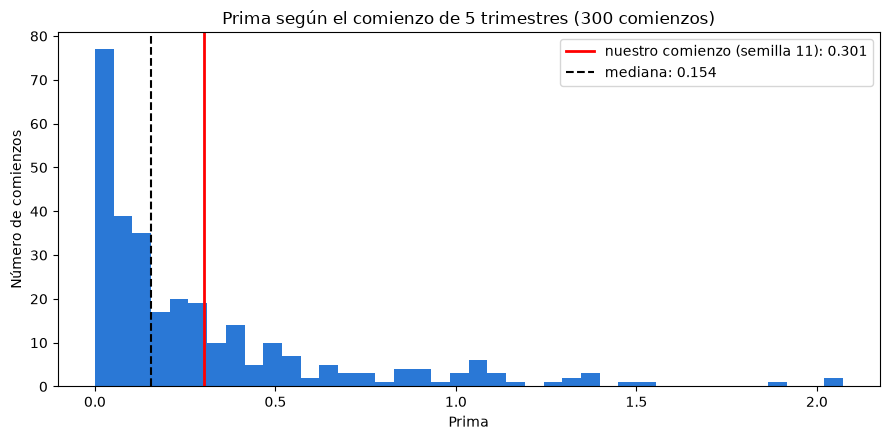

media 0.302 | mediana 0.154 | desv. típica 0.372
percentiles 5/95: [0.002 1.087] | min/max: 0.0003 2.07


In [18]:
def prima_con_semilla(semilla, n=5_000):
    r = np.random.default_rng(semilla)
    Z1 = r.standard_normal((n_comunes, 3)) @ L.T
    s1 = np.empty((n_comunes + 1, 3)); s1[0] = S0
    s1[1:] = np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z1 * np.sqrt(dt))
    s1 = np.cumprod(s1, axis=0)
    Z2 = r.standard_normal((n, n_resto, 3)) @ L.T
    s2 = np.empty((n, n_resto + 1, 3)); s2[:, 0] = s1[-1]
    s2[:, 1:] = np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z2 * np.sqrt(dt))
    s2 = np.cumprod(s2, axis=1)
    x = np.concatenate([np.broadcast_to(s1[1:], (n, n_comunes, 3)), s2[:, 1:]], axis=1)
    cesta_ = np.exp(np.log(x / S0).mean(axis=1)).sum(axis=1)
    return np.exp(-mu * T) * np.maximum(cesta_ - E, 0).mean()

primas = np.array([prima_con_semilla(1000 + s) for s in range(300)])

plt.figure(figsize=(9, 4.5))
plt.hist(primas, bins=40, color="#2a78d6")
plt.axvline(prima, color="red", lw=2, label=f"nuestro comienzo (semilla 11): {prima:.3f}")
plt.axvline(np.median(primas), color="black", lw=1.5, ls="--", label=f"mediana: {np.median(primas):.3f}")
plt.xlabel("Prima"); plt.ylabel("Número de comienzos")
plt.title("Prima según el comienzo de 5 trimestres (300 comienzos)"); plt.legend(); plt.tight_layout()
plt.savefig("figuras/mc_comienzos.png", dpi=200); plt.show()
print(f"media {primas.mean():.3f} | mediana {np.median(primas):.3f} | desv. típica {primas.std():.3f}")
print("percentiles 5/95:", np.percentile(primas, [5, 95]).round(3), "| min/max:", primas.min().round(4), primas.max().round(2))

### 9.3 Comprobación del generador

In [19]:
lr = np.log(S2[:, 1:] / S2[:, :-1]).reshape(-1, 3)    # log-rentabilidades trimestrales del tramo aleatorio
c_sim = np.corrcoef(lr.T)
validacion = pd.DataFrame({
    "sigma objetivo": sigma, "sigma simulada": lr.std(axis=0) / np.sqrt(dt),
    "E[S20/S5] objetivo": np.exp(mu * n_resto * dt),
    "E[S20/S5] simulado": S2[:, -1].mean(axis=0) / S2[0, 0],
}, index=acciones).round(4)
display(validacion)
print("rho simulada (WMT-MRK, WMT-NVDA, MRK-NVDA):", c_sim[0, 1].round(3), c_sim[0, 2].round(3), c_sim[1, 2].round(3))

,sigma objetivo,sigma simulada,E[S20/S5] objetivo,E[S20/S5] simulado
WMT,0.2192,0.2192,1.0382,1.0415
MRK,0.2359,0.2360,1.0382,1.0391
NVDA,0.5174,0.5169,1.0382,1.0369


rho simulada (WMT-MRK, WMT-NVDA, MRK-NVDA): 0.234 0.225 0.129
